# Vanilla Neural Network

In this notebook, we implement a simple **vanilla neural network** from scratch using only NumPy, without relying on high-level deep learning libraries. The goal is to understand the fundamental mathematical operations behind neural networks, including the forward pass, loss computation, backpropagation, and parameter updates.

The architecture consists of:

- an **input layer** containing two input features,
- a single **hidden layer** (with $h$ neurons) with sigmoid activation,
- and an **output layer** for binary classification.

For an input feature matrix:

$$
X \in \mathbb{R}^{n \times f}
$$

the network performs the following operations:

$$
Z_1 = XW_1 + b_1
$$

$$
A_1 = \sigma(Z_1)
$$

$$
Z_2 = A_1W_2 + b_2
$$

$$
A_2 = \sigma(Z_2)
$$

where:

- \(W_1, W_2\) are the trainable weight matrices,
- \(b_1, b_2\) are the bias vectors,
- and \(\sigma(x)\) is the sigmoid activation function.

The network is trained using **binary cross-entropy loss**:

$$
L = -\frac1n \sum_i \left[
Y_i\log(A_{2,i})
+
(1-Y_i)\log(1-A_{2,i})
\right]
$$

To optimize the parameters, we use **backpropagation**, which applies the chain rule of calculus to compute gradients of the loss function with respect to every parameter in the network. These gradients indicate how each parameter contributes to the prediction error.

The parameters are then updated using gradient descent:

$$
W \leftarrow W - \eta \frac{\partial L}{\partial W}
$$

$$
b \leftarrow b - \eta \frac{\partial L}{\partial b}
$$

where \(\eta\) is the learning rate.

Although this is a small neural network, it contains all the essential components used in larger deep learning architectures:
- linear transformations,
- nonlinear activations,
- differentiable loss functions,
- gradient computation,
- and iterative optimization.

Building the network from scratch provides a clear understanding of how information flows forward through the network and how errors propagate backward during learning.
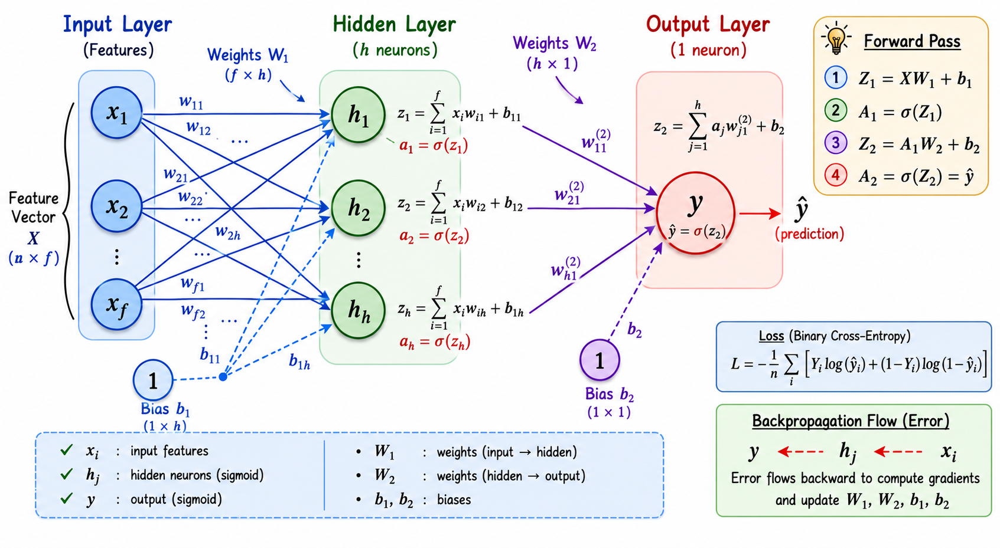

In [1]:
import numpy as np
import matplotlib.pyplot as plt

1.3322676295501878e-16 1.0
-9.547918011776346e-16 1.0


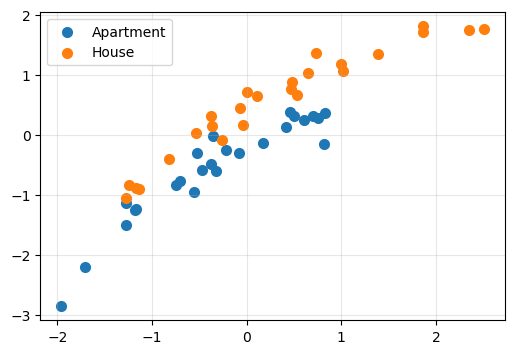

In [2]:
#Load the housing data
housing_data = np.loadtxt('./data/housing_price_labelled.txt',skiprows=1,delimiter=',')
sizes = housing_data[:,0]
prices = housing_data[:,1]
labels = housing_data[:,2].astype(int)
sizes_scaled = (sizes - np.mean(sizes) ) / np.std(sizes)
prices_scaled = (prices - np.mean(prices) ) / np.std(prices)

print(sizes_scaled.mean(),sizes_scaled.std())
print(prices_scaled.mean(),prices_scaled.std())

# Plotting
fig = plt.figure(figsize=(6,4))
axis = fig.add_subplot(1,1,1)
axis.scatter(sizes_scaled[labels==0], prices_scaled[labels==0], linewidth=2, label='Apartment')
axis.scatter(sizes_scaled[labels==1], prices_scaled[labels==1], linewidth=2, label='House')

axis.legend()
axis.grid(alpha=0.3)
plt.show()

In [3]:
features = [sizes_scaled, prices_scaled]
feature_matrix = np.array(features).T 

feature_labels = ['sizes','prices']
feature_matrix.shape


(50, 2)

# Shapes

$$
X:(n\times f), \quad
W_1:(f\times h), \quad
b_1:(1\times h)
$$

$$
Z_1:(n\times h), \quad
A_1:(n\times h)
$$

$$
W_2:(h\times o), \quad
b_2:(1\times o)
$$

$$
Z_2:(n\times o), \quad
A_2:(n\times o), \quad
Y:(n\times o)
$$

---

# Forward Pass

$$
Z_1 = XW_1 + b_1
$$

$$
(Z_1)_{ib} = \sum_a X_{ia}(W_1)_{ab} + (b_1)_b
$$

$$
A_1 = \sigma(Z_1)
$$

$$
(A_1)_{ib} = \sigma((Z_1)_{ib})
$$

$$
\sigma(x)=\frac{1}{1+e^{-x}}
$$

$$
Z_2 = A_1W_2 + b_2
$$

$$
(Z_2)_{io} = \sum_b (A_1)_{ib}(W_2)_{bo} + (b_2)_o
$$

$$
A_2 = \sigma(Z_2)
$$

$$
(A_2)_{io} = \sigma((Z_2)_{io})
$$

---

# Loss Function

$$
L = -\frac1n \sum_i \left[ Y_i\log(A_{2,i}) + (1-Y_i)\log(1-A_{2,i}) \right]
$$

---

# Backward Pass

## Output Layer

$$
dZ_2 = \frac1n(A_2-Y)
$$

$$
\frac{\partial L}{\partial (Z_2)_{io}}
=
\frac1n\left((A_2)_{io}-Y_{io}\right)
$$

$$
dW_2 = A_1^TdZ_2
$$

$$
\frac{\partial L}{\partial (W_2)_{bo}}
=
\sum_i (A_1)_{ib}(dZ_2)_{io}
$$

$$
db_2 = \sum_i dZ_{2,i}
$$

$$
\frac{\partial L}{\partial (b_2)_o}
=
\sum_i (dZ_2)_{io}
$$

---

## Hidden Layer

$$
dA_1 = dZ_2W_2^T
$$

$$
\frac{\partial L}{\partial (A_1)_{ib}}
=
\sum_o (dZ_2)_{io}(W_2)_{bo}
$$

$$
dZ_1 = (dA_1)\odot A_1(1-A_1)
$$

$$
dZ_1 = (dZ_2W_2^T)\odot A_1(1-A_1)
$$

$$
\frac{\partial L}{\partial (Z_1)_{ib}}
=
\frac{\partial L}{\partial (A_1)_{ib}}
(A_1)_{ib}(1-(A_1)_{ib})
$$

$$
\frac{\partial L}{\partial (Z_1)_{ib}}
=
(dZ_2)_i(W_2)_b(A_1)_{ib}(1-(A_1)_{ib})
$$

$$
dW_1 = X^TdZ_1
$$

$$
\frac{\partial L}{\partial (W_1)_{ab}}
=
\sum_i X_{ia}(dZ_1)_{ib}
$$

$$
\frac{\partial L}{\partial (W_1)_{ab}}
=
\sum_i X_{ia}(dZ_2)_i(W_2)_b(A_1)_{ib}(1-(A_1)_{ib})
$$

$$
db_1 = \sum_i dZ_{1,i}
$$

$$
\frac{\partial L}{\partial (b_1)_b}
=
\sum_i (dZ_1)_{ib}
$$

In [4]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    s = 1 / (1 + np.exp(-z))
    return s

class NeuralNetwork():
    def __init__(self, input_size=2, output_size=1, hidden_layer=6):
        self.input_size = input_size
        self.output_size = output_size
        self.hidden_layer = hidden_layer

        print("input_size ", self.input_size)
        print("output_size ", self.output_size)
        print("hidden_layer ", self.hidden_layer)
        
        # Initialise weights and biases
        self.W1 = np.random.randn(self.input_size, self.hidden_layer)
        self.b1 = np.zeros((1, self.hidden_layer))
        self.W2 = np.random.randn(self.hidden_layer, self.output_size)
        self.b2 = np.zeros((1, self.output_size))

        
    def forward_pass(self, feature_matrix):
        
        # 1st Layer 
        Z1 = feature_matrix @ self.W1 + self.b1
        A1 = sigmoid(Z1)
        
        # Output Layer
        Z2 = A1 @ self.W2 + self.b2
        A2 = sigmoid(Z2)

        
        cache = { # Use dictionary
            'Z1': Z1,
            'A1': A1,
            'Z2': Z2,
            'A2': A2
        }
        
        return A2, cache

    def backward_pass(self, feature_matrix, y_true, cache):
        y_true = y_true.reshape(-1,1)
            
        Z1 = cache['Z1']
        A1 = cache['A1']
        Z2 = cache['Z2']
        A2 = cache['A2']
        
        # No. of samples
        n = y_true.shape[0]
        
        dZ2 = (A2 - y_true) / n  # [n x 1]

        dW2 = A1.T @ dZ2 # [h x 1] = A1.T[h x n] dZ2[n x 1]
        db2 = np.sum(dZ2, axis=0, keepdims=True) 

        dA1 = dZ2 @ self.W2.T # [n x h] = dZ2[n x 1] W2.T[1 x h]
        
        dZ1 = dA1 * A1 * (1 - A1)  # element wise multiplication [n x h] = dA1[n x h] A1[n x h] (1 - A1) [n x h]  
        dW1 = feature_matrix.T @ dZ1 # [f x h] = X.T[f x n] dZ1[n x h]
        db1 = np.sum(dZ1, axis=0, keepdims=True) # [1 x h]
        
        gradients = {
            "dW1": dW1,
            "db1": db1,
            "dW2": dW2,
            "db2": db2
        }
    
        return gradients
    
    def calculate_loss(self, y_true, y_pred):
        """Calculate binary cross-entropy loss"""
        epsilon = 1e-15
        y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
        loss = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
        return loss

         
    def updateparameters(self, gradients, learning_rate):
        # Gradient descent update
        self.W1 -= learning_rate * gradients['dW1']
        self.b1 -= learning_rate * gradients['db1']
        self.W2 -= learning_rate * gradients['dW2']
        self.b2 -= learning_rate * gradients['db2']

        
    def train(self, feature_matrix, labels, niterations=100,learning_rate = 0.1):
        
        loss_history = []
        W1_history = []
        b1_history = []
        W2_history = []
        b2_history = []
        
        for i in range(niterations):
            y_pred, cache = self.forward_pass(feature_matrix)
            loss = self.calculate_loss(labels.reshape(-1,1), y_pred)
            gradients = self.backward_pass(feature_matrix, labels, cache)
            
            self.updateparameters(gradients, learning_rate)
            
            # Store parameter history
            loss_history.append(loss)
            W1_history.append(self.W1.copy())
            b1_history.append(self.b1.copy())
            W2_history.append(self.W2.copy())
            b2_history.append(self.b2.copy())
            # Print loss
            if i % 100 == 0:
                print(f"Iteration {i}, Loss: {loss:.5f}")
                
        return loss_history, W1_history, b1_history, W2_history, b2_history   

# Create a seperate func to plot decision boundary for animation
def forward_pass_with_params(X, W1, b1, W2, b2):

    z1 = X @ W1 + b1
    a1 = sigmoid(z1)
    z2 = a1 @ W2 + b2
    y_pred = sigmoid(z2)
    prediction = (y_pred >= 0.5).astype(int)
    return y_pred, prediction

In [5]:
NN = NeuralNetwork(input_size=feature_matrix.shape[1], hidden_layer=8, output_size=1)
loss_history, W1_history, b1_history, W2_history, b2_history = NN.train(feature_matrix, labels, niterations=200, learning_rate=1.5)

input_size  2
output_size  1
hidden_layer  8
Iteration 0, Loss: 0.86305
Iteration 100, Loss: 0.25215


In [6]:
print(W1_history[0].shape)

(2, 8)


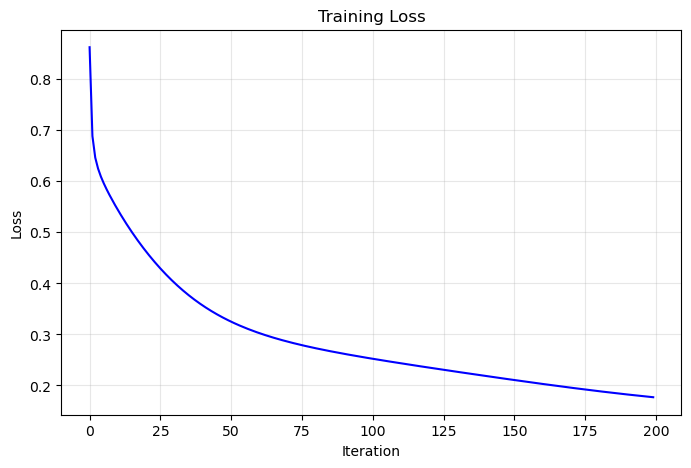

In [7]:
plt.figure(figsize=(8,5))
plt.plot(loss_history,'b-')
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)
plt.show()

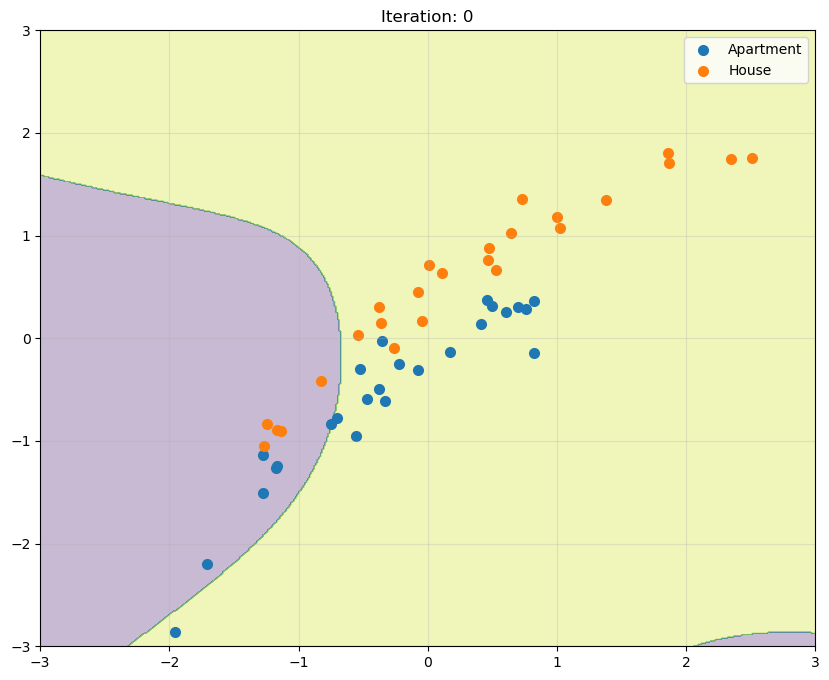

In [8]:
import matplotlib.animation as animation

from IPython.display import HTML

# ---------------------------------------
# Create mesh grid
# ---------------------------------------

x1 = np.linspace(-3, 3, 500)
x2 = np.linspace(-3, 3, 500)

X1, X2 = np.meshgrid(x1, x2)

grid_points = np.c_[X1.ravel(), X2.ravel()]

fig, axis = plt.subplots(figsize=(10,8))

# ---------------------------------------
# Animation function
# ---------------------------------------

def animate(frame):

    axis.clear()

    # Current parameters
    W1 = W1_history[frame]
    b1 = b1_history[frame]
    W2 = W2_history[frame]
    b2 = b2_history[frame]

    # Prediction on grid
    y_prob, y_class = forward_pass_with_params(grid_points, W1, b1, W2, b2)

    # Reshape back to mesh shape
    Z = y_class.reshape(X1.shape)

    # Decision boundary
    axis.contourf(X1, X2, Z, alpha=0.3)

    # Training points
    axis.scatter(sizes_scaled[labels==0], prices_scaled[labels==0], linewidth=2, label='Apartment')
    axis.scatter(sizes_scaled[labels==1], prices_scaled[labels==1], linewidth=2, label='House')

    axis.set_title(f"Iteration: {frame}")

    axis.legend()
    axis.grid(alpha=0.3)

# ---------------------------------------
# Create animation
# ---------------------------------------

anim = animation.FuncAnimation(fig, animate, frames=len(W1_history), interval=200)
anim.save("neuralnetwork_boundary.gif")
HTML(anim.to_jshtml())

In [9]:
# saving to m4 using ffmpeg writer
#writervideo = animation.FFMpegWriter(fps=60)
#anim.save('vanilla_nn.mp4', writer=writervideo)